# 05 – Support Vector Regression (RBF-Kernel)

**Ziel:** SVR als dritte ML-Methode — kernel-basiert, methodisch anders als RF/XGBoost.

**Wichtige Unterschiede zu RF und XGBoost:**
- Distanzbasiert → **Standardisierung ist Pflicht** (RF/XGBoost brauchten das nicht)
- Quadratische Rechenkomplexität O(n²) → deutlich langsamer als RF/XGBoost
- Trotzdem auf dem **vollen Trainingsdatensatz (24.320 Zeilen)** trainiert: die Laufzeit ist praktikabel, und ein Sub-Sample würde den Vergleich zugunsten der Baummodelle verzerren

**Erwartung:** SVR wird schlechter als XGBoost abschneiden — das ist bekannt  
und macht die Vergleichstabelle interessanter, nicht schwächer.

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, GroupKFold

from src.data.loader import load_train, load_test, get_feature_cols
from src.evaluation.metrics import evaluate_all
from src.config import SVR_PARAMS, REPORTS

sns.set_theme(style='whitegrid')
print('Setup fertig.')

Setup fertig.


## 1. Daten laden

In [2]:
train = load_train()
test  = load_test()

# SVR: normalisierte Features aus R verwenden (Sensoren bereits auf [0,1])
# Alternativ: raw+rolling mit StandardScaler in der Pipeline
# Wir nehmen raw+rolling und skalieren in der Pipeline — so ist der
# Scaler korrekt innerhalb der Cross-Validation (kein Leakage)
feature_cols = get_feature_cols('raw+rolling')

X_train_full = train[feature_cols]
y_train_full = train['RUL']
groups_full  = train['unit_number']

X_test  = test[feature_cols]
y_test  = test['RUL_true']

print(f'Voller Train: {X_train_full.shape}')

Train geladen: 24320 Zeilen (400 Rolling-NAs entfernt)
Test geladen: 100 Zeilen (eine pro Engine)
Voller Train: (24320, 36)


## 2. Trainingsdaten für SVR (voller Datensatz)

SVR mit RBF-Kernel hat O(n²) Komplexität. Ursprünglich war deshalb ein Sub-Sample von 10.000 Zeilen geplant.  
Im finalen Lauf wird **der volle Datensatz mit 24.320 Zeilen** verwendet: Die Laufzeit war praktikabel,  
und ein Sub-Sample hätte SVR gegenüber RF/XGBoost systematisch benachteiligt.

Der Sampling-Code bleibt als Option erhalten: `SUBSAMPLE_N = len(train)` entspricht dem vollen Datensatz,  
ein kleinerer Wert (z. B. 10_000) aktiviert engine-weises Sub-Sampling.

In [3]:
SUBSAMPLE_N = len(train)   # = 24.320 → voller Datensatz (wie im Originallauf)
rng = np.random.default_rng(42)

# Engine-weise sampeln: aus jeder Engine proportional Zeilen nehmen
sample_idx = (
    train.groupby('unit_number')
    .apply(lambda g: g.sample(
        n=max(1, int(len(g) * SUBSAMPLE_N / len(train))),
        random_state=42
    ))
    .index.get_level_values(1)
)

X_train = X_train_full.loc[sample_idx]
y_train = y_train_full.loc[sample_idx]
groups  = groups_full.loc[sample_idx]

print(f'Sub-Sample: {X_train.shape} ({len(groups.unique())} Engines vertreten)')

Sub-Sample: (24320, 36) (100 Engines vertreten)


## 3. SVR Pipeline

**Pipeline ist hier Pflicht**, nicht optional:  
Der StandardScaler muss auf jedem CV-Fold separat auf die Train-Daten gefittet werden.  
Wenn man den Scaler vorher auf alle Trainingsdaten fittet und dann CV macht,  
fließen die Mittelwerte/Std der Validation-Daten ins Training ein → Information Leakage.

In [4]:
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr',    SVR(kernel='rbf'))
])

# Baseline mit Default-Parametern
svr_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr',    SVR(**SVR_PARAMS))
])
svr_baseline.fit(X_train, y_train)

y_pred_baseline = svr_baseline.predict(X_test)
results_baseline = evaluate_all(y_test.values, y_pred_baseline, 'SVR Baseline')
print(results_baseline)

{'Model': 'SVR Baseline', 'RMSE': 21.55, 'MAE': 16.2, 'R²': 0.729, 'NASA Score': 2400.8}


## 4. Hyperparameter-Tuning

In [5]:
param_grid_svr = {
    'svr__C':       [1, 10, 100],
    'svr__gamma':   ['scale', 0.01, 0.1],
    'svr__epsilon': [1, 5, 10],
}

# 3 Folds statt 5 — SVR ist langsam, 3 reichen für stabile Schätzung
grid_svr = GridSearchCV(
    svr_pipeline,
    param_grid_svr,
    cv=GroupKFold(n_splits=3),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)
grid_svr.fit(X_train, y_train, groups=groups)

print(f'Beste Parameter: {grid_svr.best_params_}')
print(f'Bestes CV-RMSE:  {-grid_svr.best_score_:.2f}')

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Beste Parameter: {'svr__C': 10, 'svr__epsilon': 10, 'svr__gamma': 0.01}
Bestes CV-RMSE:  16.92


## 5. Evaluation auf Test-Set

In [6]:
best_svr = grid_svr.best_estimator_
y_pred_svr = best_svr.predict(X_test)

results_svr = evaluate_all(y_test.values, y_pred_svr, 'SVR (RBF)')
print(pd.DataFrame([results_svr]).set_index('Model').to_string())

            RMSE    MAE    R²  NASA Score
Model                                    
SVR (RBF)  21.12  15.73  0.74      1809.1


## 6. Predicted vs. Actual

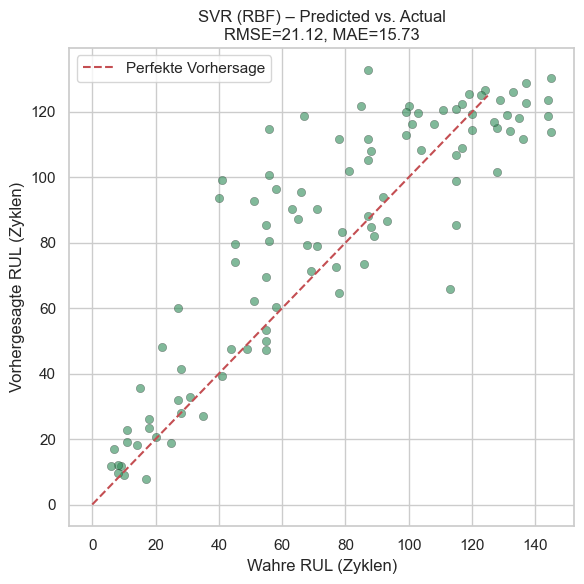

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_svr, alpha=0.6, color='seagreen', edgecolors='k', linewidths=0.3)
ax.plot([0, 125], [0, 125], 'r--', label='Perfekte Vorhersage')
ax.set_xlabel('Wahre RUL (Zyklen)')
ax.set_ylabel('Vorhergesagte RUL (Zyklen)')
ax.set_title(f'SVR (RBF) – Predicted vs. Actual\nRMSE={results_svr["RMSE"]}, MAE={results_svr["MAE"]}')
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / 'svr_predicted_vs_actual.png', dpi=150)
plt.show()

## 7. Ergebnisse speichern

In [8]:
from src.evaluation.results import save_results, save_predictions

# Metriken → model_results.json, Vorhersagen pro Engine → predictions_test.csv
save_results(results_svr)
save_predictions('SVR (RBF)', test['unit_number'], y_test, y_pred_svr)

Metriken gespeichert: model_results.json → {'Model': 'SVR (RBF)', 'RMSE': 21.12, 'MAE': 15.73, 'R²': 0.74, 'NASA Score': 1809.1}
Vorhersagen gespeichert: predictions_test.csv (Spalte 'SVR (RBF)')
